# Week 3: Buy-and-hold backtest

Verification notebook for `idxlab.backtest.buy_and_hold` and `idxlab.backtest.metrics`.

Rules of the backtest (also in the function's docstring):
- Equal weight across all tickers, bought on the first date, never traded again
- Uses adjusted `close` for returns
- No costs, no lot rounding (those arrive in Week 4)
- Only dates where every ticker has a price are used

This is a **verification run, not a benchmark**.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from idxlab.backtest.buy_and_hold import buy_and_hold
from idxlab.backtest.metrics import cagr, max_drawdown, total_return

df = pd.read_parquet("../data/sample/prices_sample.parquet")
print(df.shape)
print(df["ticker"].value_counts())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

(2425, 10)
ticker
ASII    485
BBCA    485
BBRI    485
BMRI    485
UNTR    485
Name: count, dtype: int64
Date range: 2022-01-03 to 2023-12-29


## 2. Hand-calculation check (BBCA)

Step 1: look at the first and last close for one stock.

In [2]:
bbca = df[df["ticker"] == "BBCA"].sort_values("date")

first, last = bbca.iloc[0], bbca.iloc[-1]
print("First:", first["date"].date(), first["close"])
print("Last: ", last["date"].date(), last["close"])

First: 2022-01-03 6253.10791015625
Last:  2023-12-29 8382.548828125


Step 2: work out `last / first - 1` by hand in a calculator

| | Value |
|---|---|
| First close | 6253.10791015625 |
| Last close | 8382.548828125 |
| Last / First - 1 (by hand) | 0.3405423074 |

Step 3: run the function on the same stock and compare.

In [3]:
equity = buy_and_hold(bbca)
by_function = total_return(equity)
by_hand = last["close"] / first["close"] - 1

print("Function:", by_function)
print("By hand: ", by_hand)
assert abs(by_function - by_hand) < 1e-9, "Mismatch: the engine and the hand calculation disagree"
print("Match.")

Function: 0.3405412074386447
By hand:  0.3405412074386447
Match.


## 3. All 5 tickers

Equal-weight portfolio of everything in the sample.

In [4]:
portfolio = buy_and_hold(df)

print("Total return:", round(total_return(portfolio), 4))
print("CAGR:        ", round(cagr(portfolio), 4))
print("Max drawdown:", round(max_drawdown(portfolio), 4))
print("Days used:   ", len(portfolio))

Total return: 0.4575
CAGR:         0.209
Max drawdown: -0.1549
Days used:    485


The black line (portfolio) should sit between the individual stocks, and dip when they dip.
If it ends outside the range of the individual stocks, something is wrong.

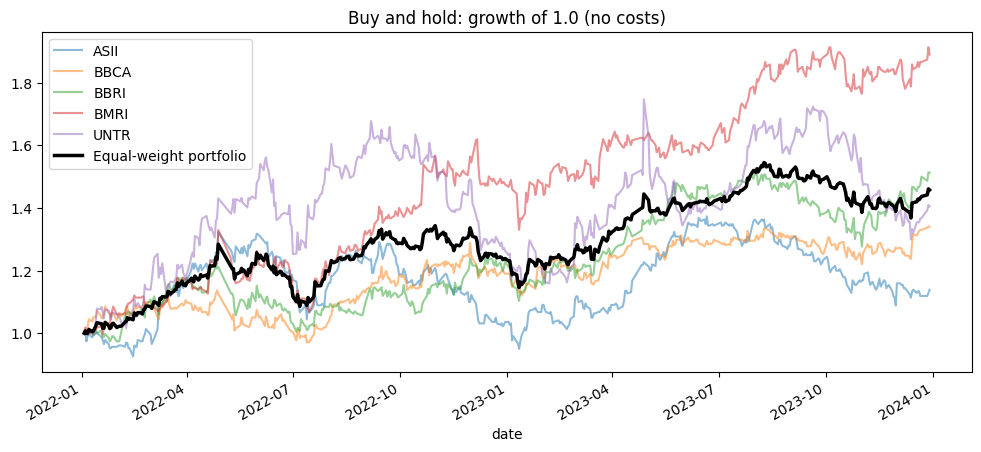

In [5]:
wide = df.pivot(index="date", columns="ticker", values="close").dropna()

fig, ax = plt.subplots(figsize=(12, 5))
(wide / wide.iloc[0]).plot(ax=ax, alpha=0.5)
portfolio.plot(ax=ax, color="black", linewidth=2.5, label="Equal-weight portfolio")
ax.legend()
ax.set_title("Buy and hold: growth of 1.0 (no costs)")
plt.show()

## 4. Drawdown

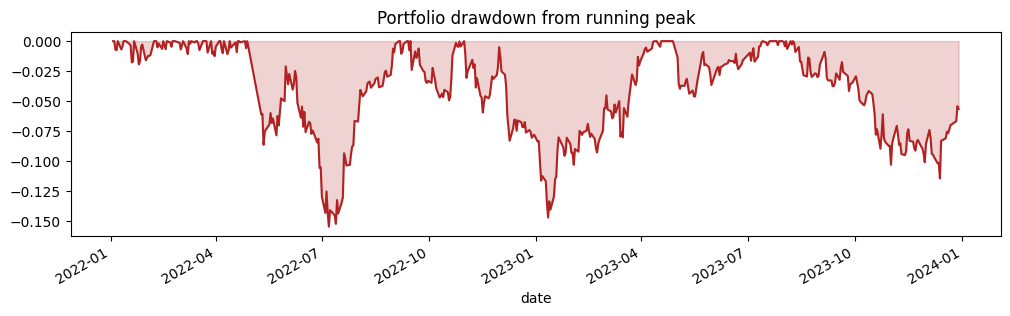

Worst day for the drawdown: 2022-07-07 -0.1549


In [6]:
drawdown = portfolio / portfolio.cummax() - 1

fig, ax = plt.subplots(figsize=(12, 3))
drawdown.plot(ax=ax, color="firebrick")
ax.fill_between(drawdown.index, drawdown, 0, color="firebrick", alpha=0.2)
ax.set_title("Portfolio drawdown from running peak")
plt.show()

print("Worst day for the drawdown:", drawdown.idxmin().date(), round(drawdown.min(), 4))

## 5. Data check: do all tickers share the same dates?

`buy_and_hold` drops any date where a ticker is missing. If many dates are dropped, that matters for Week 4.

In [7]:
rows_per_ticker = df.groupby("ticker")["date"].nunique()
print(rows_per_ticker)
print("Dates dropped by dropna():", rows_per_ticker.max() - len(portfolio))

ticker
ASII    485
BBCA    485
BBRI    485
BMRI    485
UNTR    485
Name: date, dtype: int64
Dates dropped by dropna(): 0


## Notes

- What did the drawdown look like, and when was the worst point? 

The maximum drawdown was -15.49% on 2022-07-07. There were three separate dips (the figures are read off the chart, so they are approximate):
May to July 2022: the deepest, bottoming at -15.5% in early July. The portfolio recovered most of it by September.
Late 2022 to January 2023: about -14.7% at the low in early January 2023.
October to November 2023: about -11.5% at the worst point, and the sample ended 2023 still about 5.5% below its peak.
Between April and August 2023 the portfolio set new highs (peaking near 1.54 in August), which is why the drawdown chart touches zero there. Even with a final return of +45.8%, the path included several months of double-digit losses.

- Did `dropna()` remove any dates? What should Week 4 do about that?

No. Every ticker has 485 rows for 2022-01-03 to 2023-12-29, and 485 dates were used, so 0 were dropped. That won’t hold for all 45 LQ45 tickers. Recent listings such as WIFI and DEWA will have shorter histories, and dropna() would cut the whole portfolio back to the date range where all of them have data.

Week 4 should report how many dates and tickers are dropped each run, so a silent cut never goes unnoticed. Let a stock join the portfolio on the first date it has data, instead of requiring every stock from day one. Or keep a fixed universe of tickers with full history for the benchmark, and document the others as excluded. Note that the universe is today’s LQ45 applied to past dates, so the results have some hindsight bias.